# PreTest 03: Multiclass Classification — การจำแนกสายพันธุ์นกเพนกวิน
### Pipeline + ColumnTransformer · KNN / SVM / Gradient Boosting · GridSearchCV / RandomizedSearchCV · Metrics หลายคลาส

> **ที่มา:** EDA ดัดแปลงจาก Kaggle Notebook [penguin dataset : The new Iris](https://www.kaggle.com/code/parulpandey/penguin-dataset-the-new-iris) โดย Parul Pandey
> ส่วน Modeling, Evaluation และ Tuning เขียนเพิ่มทั้งหมด พร้อมคำอธิบายภาษาไทย
>
> **ชุดข้อมูล (Dataset):** [Palmer Archipelago (Antarctica) Penguin Data](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data) — เพนกวิน 344 ตัว 3 สายพันธุ์

---

## ความแตกต่างจาก PreTest 01

| หัวข้อ | PreTest 01 (ฝน) | PreTest 03 (เพนกวิน) |
|---|---|---|
| จำนวนคลาส | 2 (Binary) | **3 (Multiclass)** |
| เตรียมข้อมูล | ทำทีละขั้นด้วยมือ | **Pipeline + ColumnTransformer** (อัตโนมัติ ไม่ Leak) |
| โมเดล | Logistic Regression, Decision Tree, Random Forest | **KNN, SVM, Gradient Boosting** |
| Tuning | GridSearchCV | GridSearchCV + **RandomizedSearchCV** + **Validation/Learning curve** |
| Metrics | Precision/Recall ของคลาสเดียว | **Macro vs Weighted average**, Confusion Matrix 3×3 |

## โครงบทเรียน
- **Part A (ขั้นที่ 1–10):** ใช้ Feature ครบทุกตัว → ทำครบทุกขั้นตอน
- **Part B (ขั้นที่ 11):** โจทย์ยากขึ้น (ตัด Feature ที่ช่วยมากออก) → ฝึกอ่านผล Multiclass จริงจัง

---
# ขั้นที่ 1: กำหนดโจทย์
- **เป้าหมาย:** ทำนาย **สายพันธุ์** (`species`) ของเพนกวินจากขนาดร่างกาย เกาะที่อยู่ และเพศ
- **ประเภทปัญหา:** Target มี 3 ค่า (Adelie, Chinstrap, Gentoo) → **Multiclass Classification**
- **วัดผลด้วย:** Accuracy, **Macro F1** (ให้ทุกสายพันธุ์สำคัญเท่ากัน), Confusion Matrix 3×3

# ขั้นที่ 2: นำเข้าไลบรารีและโหลดข้อมูล

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [2]:
DATA_FILE = "Data/penguins_size.csv"
if not os.path.exists(DATA_FILE):
    import kagglehub   # ถ้า error ให้รัน !pip install kagglehub
    DATA_FILE = os.path.join(kagglehub.dataset_download("parulpandey/palmer-archipelago-antarctica-penguin-data"), "penguins_size.csv")

df = pd.read_csv(DATA_FILE)
print("ขนาดข้อมูล:", df.shape)
df.head()

ขนาดข้อมูล: (344, 7)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


---
# ขั้นที่ 3: สำรวจข้อมูลเบื้องต้น

| คอลัมน์ | ความหมาย | ชนิด |
|---|---|---|
| **`species`** | **สายพันธุ์ ← Target** (Adelie / Chinstrap / Gentoo) | Categorical |
| `island` | เกาะที่พบ (Biscoe / Dream / Torgersen) | Categorical |
| `culmen_length_mm` | ความยาวจะงอยปาก (มม.) | Numerical |
| `culmen_depth_mm` | ความหนาจะงอยปาก (มม.) | Numerical |
| `flipper_length_mm` | ความยาวครีบ/ปีก (มม.) | Numerical |
| `body_mass_g` | น้ำหนักตัว (กรัม) | Numerical |
| `sex` | เพศ (MALE / FEMALE) | Categorical |

> **Culmen** = สันบนของจะงอยปาก วัดได้ทั้งความยาว (length) และความหนา (depth)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [4]:
df.describe().round(1)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


In [5]:
for col in ['species', 'island', 'sex']:
    print(col, df[col].value_counts(dropna=False).to_dict())

species {'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}
island {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52}
sex {'MALE': 168, 'FEMALE': 165, nan: 10, '.': 1}


> **ข้อสังเกต:** คอลัมน์ `sex` มีค่าผิดปกติ คือ **`'.'`** 1 แถว — นี่คือ **ข้อมูลสกปรก (Dirty data)** ที่ต้องแก้ในขั้นที่ 4

---
# ขั้นที่ 4: ทำความสะอาดข้อมูล

### 4.1 แถวที่ค่าวัดหายทั้งหมด

In [6]:
df[df['culmen_length_mm'].isnull()]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


> **หมายเหตุ:** 2 แถวนี้ **ไม่มีค่าการวัดร่างกายแม้แต่ค่าเดียว** มีเพียงชื่อเกาะ → การเติมค่าเท่ากับการสร้างข้อมูลขึ้นเองเกือบทั้งแถว จึงลบออก

In [7]:
df = df.dropna(subset=['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g'])
print("ขนาดหลังลบ:", df.shape)

ขนาดหลังลบ: (342, 7)


### 4.2 แก้ค่าที่ผิดรูปแบบ (`sex = '.'`)
ค่า `'.'` ไม่ใช่เพศที่ถูกต้อง → แปลงเป็นค่าหาย (`NaN`) แล้วให้ Pipeline เติมค่าในขั้นที่ 6

In [8]:
df['sex'] = df['sex'].replace('.', np.nan)
print(df['sex'].value_counts(dropna=False).to_dict())
print("\nค่าหายที่เหลือ:\n", df.isnull().sum())

{'MALE': 168, 'FEMALE': 165, nan: 9}

ค่าหายที่เหลือ:
 species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


### 4.3 ข้อมูลซ้ำ

In [9]:
print("แถวซ้ำ:", df.duplicated().sum())

แถวซ้ำ: 0


---
# ขั้นที่ 5: EDA & Visualization

### 5.1 จำนวนแต่ละสายพันธุ์ (Class balance)

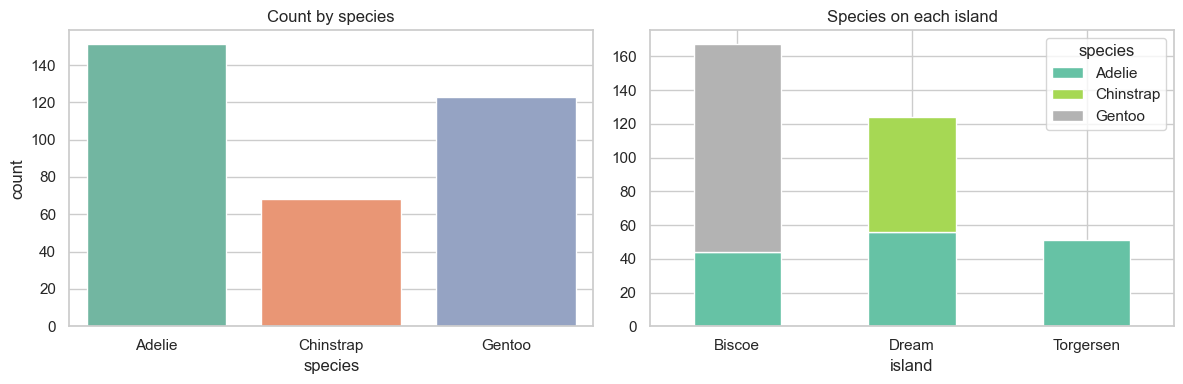

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,123
Dream,56,68,0
Torgersen,51,0,0


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='species', data=df, ax=ax[0], palette='Set2', hue='species', legend=False)
ax[0].set_title('Count by species')
pd.crosstab(df['island'], df['species']).plot(kind='bar', stacked=True, ax=ax[1], colormap='Set2')
ax[1].set_title('Species on each island'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

pd.crosstab(df['island'], df['species'])

> **ไม่สมดุลเล็กน้อย:** Chinstrap มีเพียง ~20% → ต้องใช้ `stratify` และดู **Macro F1**
> **`island` เป็นตัวบ่งชี้ที่สำคัญ:** Gentoo พบเพียงเกาะ Biscoe, Chinstrap พบเพียงเกาะ Dream, Torgersen มีแต่ Adelie

### 5.2 Pair Plot: ดูทุกคู่ตัวแปรพร้อมกัน

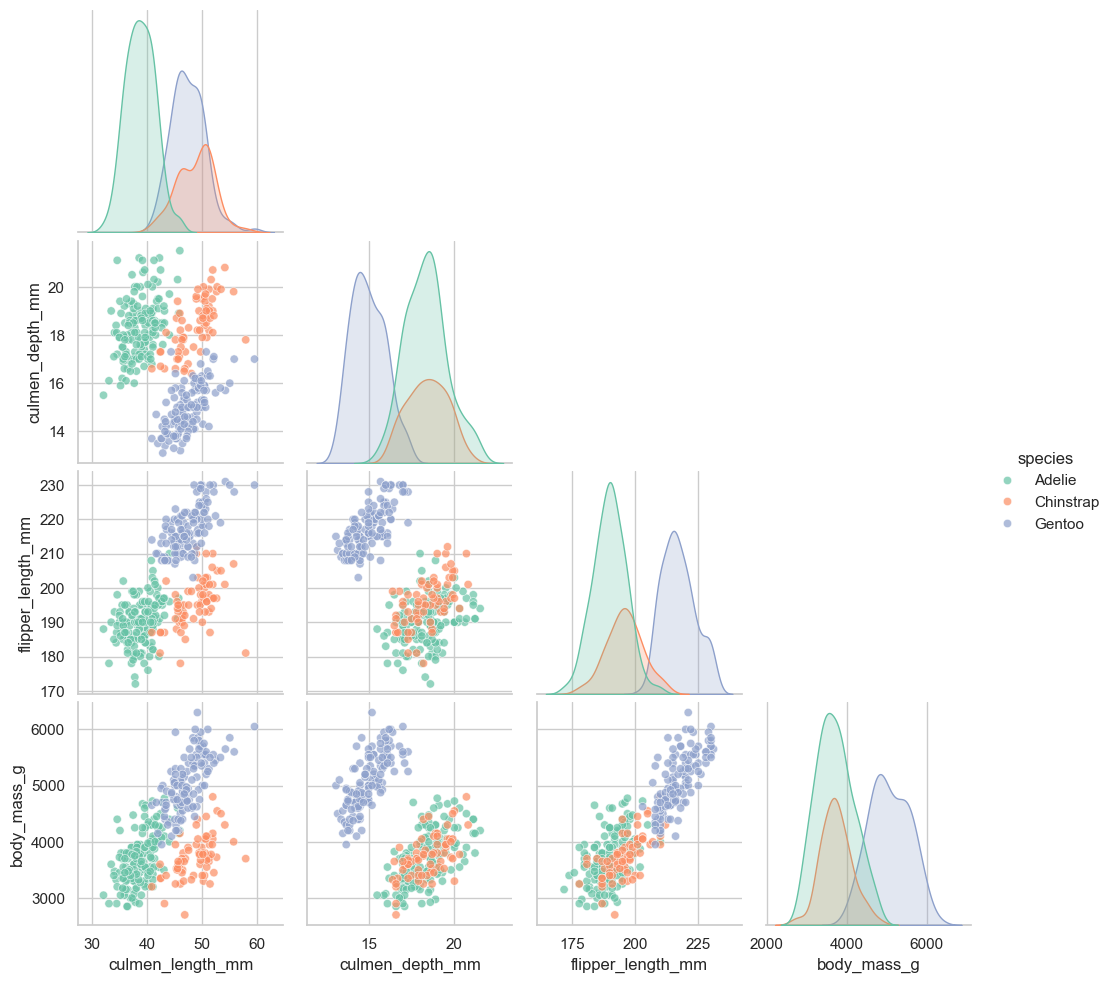

In [11]:
sns.pairplot(df, hue='species', palette='Set2', corner=True, plot_kws={'alpha': 0.7})
plt.show()

### 5.3 ตัวแปรที่แยกสายพันธุ์ได้ดี

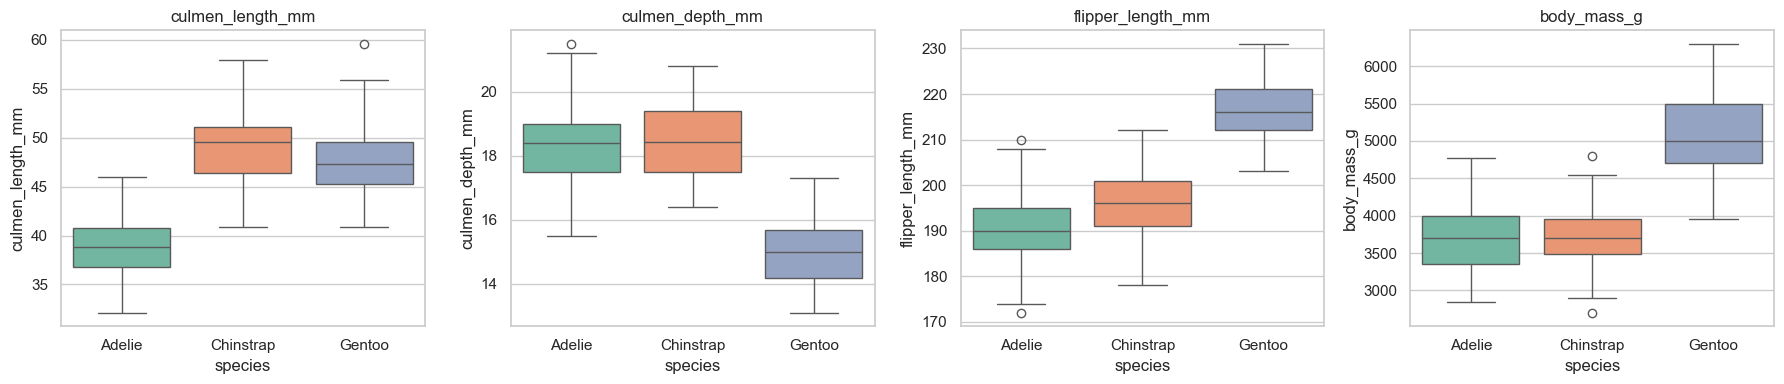

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


In [12]:
num_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='species', y=col, data=df, ax=ax, palette='Set2', hue='species', legend=False)
    ax.set_title(col)
plt.tight_layout(); plt.show()

df.groupby('species')[num_cols].mean().round(1)

> **Insight:**
> - **Gentoo** ครีบยาวและตัวหนักกว่าชัดเจน (แยกได้ง่ายที่สุด)
> - **Adelie vs Chinstrap** ขนาดตัวใกล้กันมาก แต่ **`culmen_length` (ปากยาว) ต่างกันชัด** — Chinstrap ปากยาวกว่า
> - ดังนั้น `culmen_length_mm` + `island` น่าจะเป็น Feature ที่สำคัญที่สุด

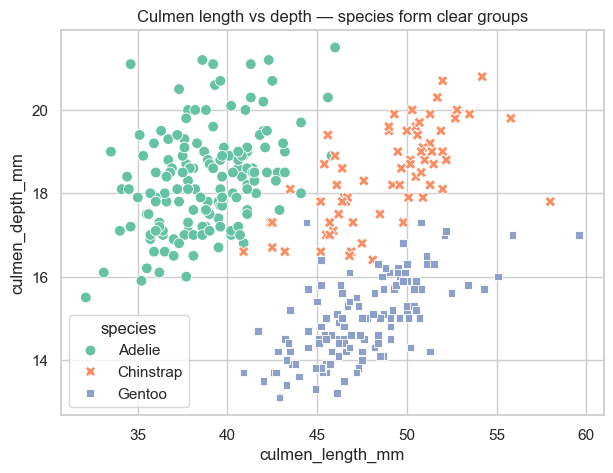

In [13]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x='culmen_length_mm', y='culmen_depth_mm', hue='species', style='species', data=df, palette='Set2', s=60)
plt.title('Culmen length vs depth — species form clear groups')
plt.show()

### 5.4 Correlation

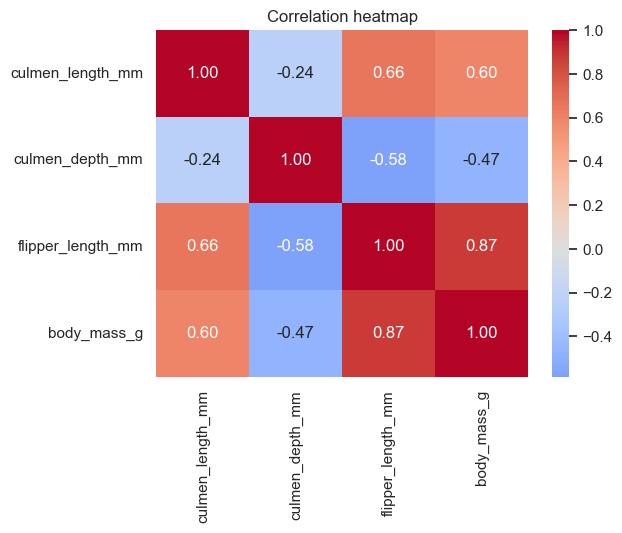

In [14]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap'); plt.show()

> **ข้อสังเกต:** `flipper_length` กับ `body_mass` สัมพันธ์กันสูง (0.87) — ตัวใหญ่ครีบก็ยาว

---
# ขั้นที่ 6: เตรียมข้อมูลด้วย Pipeline + ColumnTransformer

### เหตุผลที่ใช้ Pipeline แทนการเตรียมข้อมูลทีละขั้นแบบ PreTest 01
| ทำทีละขั้นด้วยมือ | Pipeline |
|---|---|
| ต้องจำว่า fit กับ Train แล้ว transform Test ทุกขั้น | ทำให้อัตโนมัติ |
| ทำ Cross-Validation แล้ว **Leak** ง่าย (Scale ทั้ง Train ก่อน CV) | Preprocess ใหม่ **ในทุก Fold** → ไม่ Leak |
| ข้อมูลใหม่ต้องเตรียมเองอีกรอบ | เรียก `pipe.predict(ข้อมูลดิบ)` ได้ทันที |

```
ข้อมูลดิบ ─┬─ ตัวเลข  → [เติม median] → [StandardScaler] ─┐
           └─ ข้อความ → [เติม mode]   → [OneHotEncoder]  ─┴→ [Model] → คำทำนาย
```

### 6.1 แยก X, y และแบ่ง Train/Test

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='species')
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nสัดส่วนใน Test:", y_test.value_counts(normalize=True).round(2).to_dict())

Train: (256, 6)  Test: (86, 6)

สัดส่วนใน Test: {'Adelie': 0.44, 'Gentoo': 0.36, 'Chinstrap': 0.2}


### 6.2 สร้าง Preprocessor

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
cat_features = ['island', 'sex']

def make_preprocessor(num_features, cat_features):
    numeric = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('scaler',  StandardScaler())])               # KNN / SVM ต้อง Scale
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('onehot',  OneHotEncoder(handle_unknown='ignore'))])
    transformers = [('num', numeric, num_features)]
    if cat_features:
        transformers.append(('cat', categorical, cat_features))
    return ColumnTransformer(transformers)

preprocessor = make_preprocessor(num_features, cat_features)

# ดูผลลัพธ์หลัง Preprocess (เพื่อความเข้าใจ)
preview = preprocessor.fit_transform(X_train)
pd.DataFrame(preview, columns=preprocessor.get_feature_names_out()).head().round(2)

,num__culmen_length_mm,num__culmen_depth_mm,num__flipper_length_mm,num__body_mass_g,cat__island_Biscoe,cat__island_Dream,cat__island_Torgersen,cat__sex_FEMALE,cat__sex_MALE
0,-0.64,0.03,-1.02,-0.93,0.0,1.0,0.0,0.0,1.0
1,0.18,-1.30,1.01,0.99,1.0,0.0,0.0,1.0,0.0
2,0.61,-1.44,0.58,0.49,1.0,0.0,0.0,1.0,0.0
3,-1.74,0.47,-1.02,-1.66,1.0,0.0,0.0,1.0,0.0
4,-0.60,0.62,-0.44,-0.40,0.0,1.0,0.0,0.0,1.0


### 6.3 ฟังก์ชันวัดผล (ใช้ซ้ำกับทุกโมเดล)
- **Macro F1** = เฉลี่ย F1 ของ 3 สายพันธุ์ **แบบเท่ากัน** → Chinstrap (ตัวน้อย) สำคัญเท่า Adelie
- **Weighted F1** = เฉลี่ยโดย **ถ่วงน้ำหนักตามจำนวน** → คลาสที่มีมากมีผลมากกว่า

In [17]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(model, name, X_tr, X_te):
    pred = model.predict(X_te)
    return {'Model': name,
            'Train Acc':   model.score(X_tr, y_train),
            'Test Acc':    accuracy_score(y_test, pred),
            'Macro F1':    f1_score(y_test, pred, average='macro'),
            'Weighted F1': f1_score(y_test, pred, average='weighted')}

---
# ขั้นที่ 7: โมเดลที่ 1 — K-Nearest Neighbors (KNN)

### หลักการ
ทำนายจาก **"เพื่อนบ้านที่ใกล้ที่สุด k ตัว"** — ดูเพนกวินใน Train ที่ขนาดใกล้เคียงที่สุด k ตัว แล้วโหวตว่าส่วนใหญ่เป็นสายพันธุ์อะไร
- ใช้ **ระยะทาง** → **ต้อง Scale** (มิฉะนั้น `body_mass_g` ซึ่งมีค่าหลักพันจะมีอิทธิพลเหนือตัวแปรอื่น)
- `k` น้อย → ไวต่อ noise (Overfit), `k` มาก → เรียบเกินไป (Underfit)

### 7.1 Pipeline + Cross-Validation

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipe = Pipeline([('prep', preprocessor), ('model', KNeighborsClassifier(n_neighbors=5))])
cv = cross_val_score(knn_pipe, X_train, y_train, cv=skf, scoring='f1_macro')
print("CV Macro F1 แต่ละ Fold:", cv.round(3), f"→ เฉลี่ย {cv.mean():.3f}")

CV Macro F1 แต่ละ Fold: [0.978 0.975 0.977 0.975 1.   ] → เฉลี่ย 0.981


### 7.2 Validation Curve: การเลือกค่า k
ใช้ `validation_curve` วาดคะแนน Train vs CV ที่ k ต่างๆ

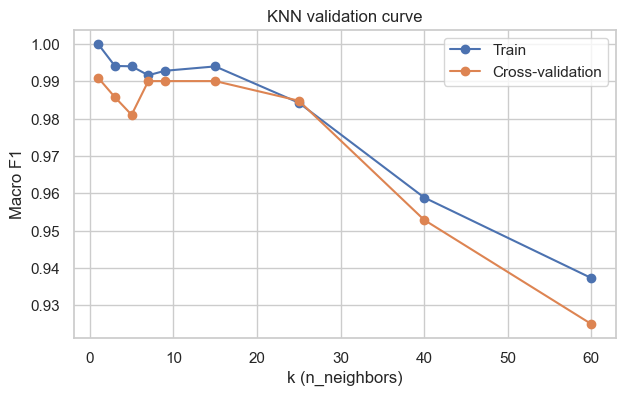

In [19]:
from sklearn.model_selection import validation_curve

k_range = [1, 3, 5, 7, 9, 15, 25, 40, 60]
train_sc, cv_sc = validation_curve(knn_pipe, X_train, y_train, param_name='model__n_neighbors',
                                   param_range=k_range, cv=skf, scoring='f1_macro')
plt.figure(figsize=(7, 4))
plt.plot(k_range, train_sc.mean(axis=1), 'o-', label='Train')
plt.plot(k_range, cv_sc.mean(axis=1), 'o-', label='Cross-validation')
plt.xlabel('k (n_neighbors)'); plt.ylabel('Macro F1'); plt.title('KNN validation curve'); plt.legend(); plt.show()

> **หมายเหตุ:** ชื่อพารามิเตอร์ใน Pipeline ใช้รูปแบบ **`ชื่อขั้น__ชื่อพารามิเตอร์`** (ขีดล่าง 2 ตัว) เช่น `model__n_neighbors`

### 7.3 GridSearchCV หา k และวิธีวัดระยะ

In [20]:
grid_knn = GridSearchCV(knn_pipe,
                        param_grid={'model__n_neighbors': [3, 5, 7, 9, 15],
                                    'model__weights': ['uniform', 'distance']},
                        cv=skf, scoring='f1_macro')
grid_knn.fit(X_train, y_train)
best_knn = grid_knn.best_estimator_
print("ค่าที่ดีที่สุด:", grid_knn.best_params_, f" CV Macro F1 = {grid_knn.best_score_:.3f}")

results = [evaluate(best_knn, 'KNN', X_train, X_test)]
pd.DataFrame(results).set_index('Model').round(3)

ค่าที่ดีที่สุด: {'model__n_neighbors': 7, 'model__weights': 'distance'}  CV Macro F1 = 0.995


,Train Acc,Test Acc,Macro F1,Weighted F1
Model,,,,
KNN,1.0,1.0,1.0,1.0


### 7.4 การวิเคราะห์ผล KNN

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| k ที่ดีที่สุด | `k = 7`, `weights='distance'` (CV Macro F1 **0.995**) | เพื่อนบ้านที่ใกล้กว่ามีสิทธิ์โหวตมากกว่า |
| Validation curve | k = 1–15 ได้ ~0.98–0.99, k ≥ 25 ลดลงเหลือ ~0.93 | k มากเกินไป → **Underfit** (เฉลี่ยจนเรียบเกินไป) |
| Test | Accuracy / Macro F1 = **1.000** (ถูกทั้ง 86 ตัว) | ทำนายถูกทั้งหมด |
| Train Acc = 1.000 แปลว่า Overfit หรือไม่ | ไม่ใช่ | เมื่อใช้ `weights='distance'` จุดใน Train ใกล้ตัวเองที่ระยะ 0 จึงได้ 100% เสมอ → **ดู CV และ Test แทน** |

> **สรุป:** KNN ทำได้สมบูรณ์แบบเพราะเพนกวินแต่ละสายพันธุ์อยู่เป็นกลุ่มชัดเจนในพื้นที่ Feature (ดูข้อ 5.2–5.3)

---
# ขั้นที่ 8: โมเดลที่ 2 — Support Vector Machine (SVM)

### หลักการ
หา **เส้นแบ่ง (Hyperplane) ที่ห่างจากทั้งสองฝั่งมากที่สุด** (Maximum margin)
- `kernel='linear'` = เส้นตรง / `kernel='rbf'` = เส้นโค้งได้
- `C` = ยอมให้ทำนายผิดได้เพียงใด (C มาก = เข้มงวด เสี่ยง Overfit)
- `gamma` (rbf) = ความโค้งของเส้น (gamma มาก = โค้งมาก เสี่ยง Overfit)
- ใช้ระยะทาง → **ต้อง Scale**, สำหรับหลายคลาส sklearn จะสร้างตัวแบ่งทีละคู่ให้อัตโนมัติ

### 8.1 RandomizedSearchCV: สุ่มทดลองค่า แทนการทดลองทุกค่า
| | GridSearchCV | RandomizedSearchCV |
|---|---|---|
| วิธี | ทดลอง **ทุก** ค่าในตาราง | **สุ่ม** ทดลอง `n_iter` ครั้งจากช่วงที่กำหนด |
| เหมาะกับ | พารามิเตอร์น้อย ค่าไม่มาก | พารามิเตอร์จำนวนมาก / ช่วงค่ากว้าง (เร็วกว่ามาก) |

In [21]:
from sklearn.svm import SVC
from scipy.stats import loguniform, randint

svm_pipe = Pipeline([('prep', preprocessor), ('model', SVC(random_state=42))])
rand_svm = RandomizedSearchCV(svm_pipe,
                              param_distributions={'model__C': loguniform(0.01, 100),
                                                   'model__gamma': loguniform(0.001, 1),
                                                   'model__kernel': ['linear', 'rbf']},
                              n_iter=30, cv=skf, scoring='f1_macro', random_state=42)
rand_svm.fit(X_train, y_train)
best_svm = rand_svm.best_estimator_
print("ค่าที่ดีที่สุด:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rand_svm.best_params_.items()})
print(f"CV Macro F1 = {rand_svm.best_score_:.3f}")

results.append(evaluate(best_svm, 'SVM', X_train, X_test))
pd.DataFrame(results).set_index('Model').round(3)

ค่าที่ดีที่สุด: {'model__C': np.float64(85.6887), 'model__gamma': np.float64(0.0251), 'model__kernel': 'linear'}
CV Macro F1 = 0.995


,Train Acc,Test Acc,Macro F1,Weighted F1
Model,,,,
KNN,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0


### 8.2 การวิเคราะห์ผล SVM

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| Hyperparameter ที่สุ่มเจอดีที่สุด | `kernel='linear'`, `C ≈ 85.7` (CV Macro F1 **0.995**) | เส้นแบ่งแบบเส้นตรงก็เพียงพอ → ข้อมูล **แยกด้วยเส้นตรงได้** (Linearly separable) |
| `gamma` | สุ่มได้ ~0.025 | ไม่มีผลเมื่อ kernel = linear (ใช้เฉพาะ rbf) |
| Test | Accuracy / Macro F1 = **1.000** | ทำนายถูกทั้งหมด |
| Overfit หรือไม่ | Train 1.000 = Test 1.000 | ไม่ |
| ใช้เวลาค้นหา | RandomizedSearchCV ทดลอง 30 ชุด (× 5 Fold) | เร็วกว่าทดลองทุกค่าแบบ Grid มาก |

> **สรุป:** SVM แบบเส้นตรงก็แยกได้ครบทั้ง 3 สายพันธุ์ — เป็นโมเดลที่เรียบง่ายและเหมาะที่สุดสำหรับข้อมูลชุดนี้

---
# ขั้นที่ 9: โมเดลที่ 3 — Gradient Boosting

### หลักการ
สร้าง Decision Tree ขนาดเล็ก **ทีละต้นต่อกัน** แต่ละต้นใหม่ **เรียนรู้จากความผิดพลาดของต้นก่อนหน้า**
(ต่างจาก Random Forest ที่สร้างหลายต้นพร้อมกันแล้วโหวต)
- `n_estimators` จำนวนต้น, `learning_rate` แต่ละต้นแก้ได้มากเพียงใด, `max_depth` ความลึกแต่ละต้น
- Tree ไม่ต้อง Scale แต่ใช้ Preprocessor เดิมได้ ไม่เสียหาย
- ตระกูลเดียวกับ **XGBoost / LightGBM** ที่ชนะการแข่งขันบ่อยๆ

In [22]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipe = Pipeline([('prep', preprocessor), ('model', GradientBoostingClassifier(random_state=42))])
rand_gb = RandomizedSearchCV(gb_pipe,
                             param_distributions={'model__n_estimators': randint(50, 300),
                                                  'model__learning_rate': loguniform(0.01, 0.3),
                                                  'model__max_depth': randint(2, 5)},
                             n_iter=20, cv=skf, scoring='f1_macro', random_state=42, n_jobs=-1)
rand_gb.fit(X_train, y_train)
best_gb = rand_gb.best_estimator_
print("ค่าที่ดีที่สุด:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rand_gb.best_params_.items()})
print(f"CV Macro F1 = {rand_gb.best_score_:.3f}")

results.append(evaluate(best_gb, 'Gradient Boosting', X_train, X_test))
pd.DataFrame(results).set_index('Model').round(3)

ค่าที่ดีที่สุด: {'model__learning_rate': np.float64(0.1206), 'model__max_depth': 2, 'model__n_estimators': 70}
CV Macro F1 = 0.985


,Train Acc,Test Acc,Macro F1,Weighted F1
Model,,,,
KNN,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0
Gradient Boosting,1.0,1.0,1.0,1.0


### 9.1 Feature Importance (ดึงจาก Pipeline)

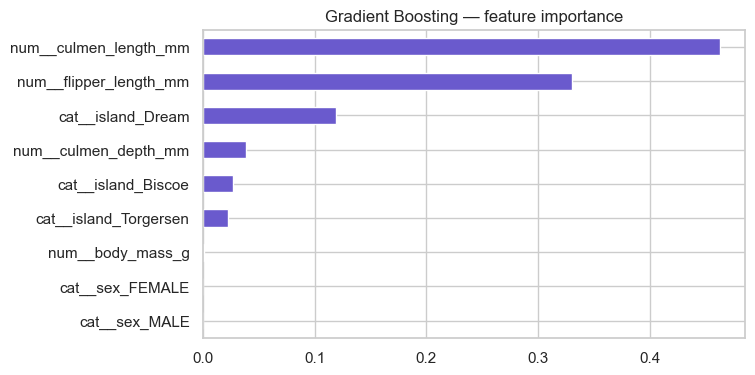

In [23]:
names = best_gb.named_steps['prep'].get_feature_names_out()
imp = pd.Series(best_gb.named_steps['model'].feature_importances_, index=names).sort_values()
imp.plot(kind='barh', figsize=(7, 4), color='slateblue', title='Gradient Boosting — feature importance')
plt.show()

### 9.2 การวิเคราะห์ผล Gradient Boosting

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| Hyperparameter ที่ดีที่สุด | 70 ต้น, `max_depth=2`, `learning_rate ≈ 0.12` | ต้นไม้ขนาดเล็กจำนวนไม่มากก็เพียงพอ |
| CV Macro F1 | **0.985** | ต่ำกว่า KNN/SVM (0.995) เล็กน้อย |
| Test | Accuracy / Macro F1 = **1.000** | ทำนายถูกทั้งหมด |
| Feature สำคัญ | `culmen_length` ~0.46 > `flipper_length` ~0.33 > `island_Dream` ~0.12 | ตรงกับ EDA: ปากยาวแยก Adelie/Chinstrap, ครีบยาวแยก Gentoo |
| Feature ที่แทบไม่ถูกใช้ | `body_mass_g`, `sex` ≈ 0 | `body_mass` ซ้ำซ้อนกับ `flipper_length` (corr 0.87) |

> **สรุป:** แม่นเท่ากันบน Test แต่ข้อดีพิเศษคือบอก **Feature Importance** ได้ — ใช้อธิบายว่าโมเดลแยกสายพันธุ์ด้วยอะไร

---
# ขั้นที่ 10: เปรียบเทียบ (Part A — Feature ครบ)

In [24]:
results_A = pd.DataFrame(results).set_index('Model').round(3)
results_A

,Train Acc,Test Acc,Macro F1,Weighted F1
Model,,,,
KNN,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0
Gradient Boosting,1.0,1.0,1.0,1.0


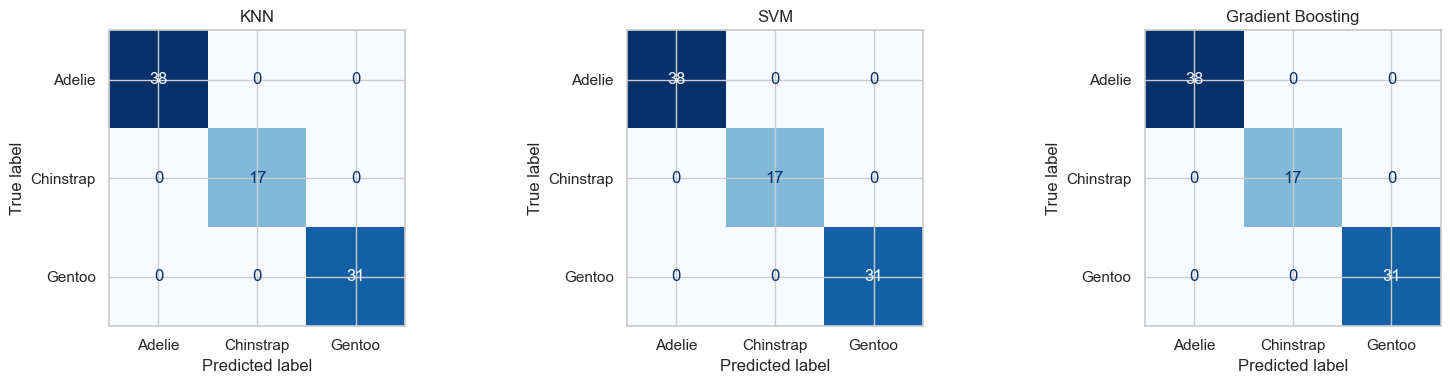

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, m) in zip(axes, [('KNN', best_knn), ('SVM', best_svm), ('Gradient Boosting', best_gb)]):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 10.1 การวิเคราะห์ผล Part A

| โมเดล | CV Macro F1 | Test Acc | Test Macro F1 |
|---|---|---|---|
| KNN | 0.995 | 1.000 | 1.000 |
| SVM | 0.995 | 1.000 | 1.000 |
| Gradient Boosting | 0.985 | 1.000 | 1.000 |

**ข้อค้นพบ**
1. **ทั้ง 3 โมเดลทำนายถูกทั้ง 86 ตัว** — Confusion Matrix ไม่มีค่าใดอยู่นอกเส้นทแยงมุม
2. **คะแนน 100% ต้องตรวจสอบ Leakage ก่อนสรุปผล:** Feature ทุกตัวเป็นค่าที่วัดจากตัวเพนกวินจริง ไม่ได้สร้างจาก `species` → **ไม่ใช่ Leakage** แต่โจทย์ง่ายจริง (ดูกราฟ 5.3: ปากยาว + ครีบยาว แยกได้เกือบสมบูรณ์)
3. **ตัดสินจาก Test ไม่ได้** เพราะเสมอกันหมด → ดู **CV** แทน: KNN = SVM (0.995) > Gradient Boosting (0.985)
4. Test มีเพียง 86 ตัว — ทำนายผิด 1 ตัว Accuracy ลด ~1.2 จุด → ความแตกต่างเพียงเล็กน้อย อาจเป็นเพียงโชค

**เลือก:** **SVM (linear)** — CV สูงสุดเท่ากับ KNN แต่เป็นเส้นแบ่งตรงที่เรียบง่ายกว่า และทำนายเร็วกว่า KNN เมื่อข้อมูลมาก
→ แต่โจทย์ง่ายเกินไปที่จะเห็นความต่างของโมเดล ไปดู **Part B** ที่ยากขึ้น

---
# ขั้นที่ 11 (Part B): โจทย์ที่ซับซ้อนขึ้น — กรณีวัดได้เฉพาะขนาดร่างกาย

**สถานการณ์:** นักวิจัยวัดได้เพียง `culmen_depth`, `flipper_length`, `body_mass` (ไม่มีความยาวปาก ไม่รู้ว่ามาจากเกาะไหน)
→ Adelie กับ Chinstrap ขนาดตัวใกล้กันมาก (ขั้นที่ 5.3) โมเดลจะสับสนหรือไม่?

### 11.1 เทรน 3 โมเดลใหม่ด้วย Feature ชุดเล็ก

In [26]:
num_B = ['culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
prep_B = make_preprocessor(num_B, [])

searches_B = {
    'KNN': GridSearchCV(Pipeline([('prep', prep_B), ('model', KNeighborsClassifier())]),
                        {'model__n_neighbors': [3, 5, 7, 9, 15, 25], 'model__weights': ['uniform', 'distance']},
                        cv=skf, scoring='f1_macro'),
    'SVM': RandomizedSearchCV(Pipeline([('prep', prep_B), ('model', SVC(random_state=42))]),
                              {'model__C': loguniform(0.01, 100), 'model__gamma': loguniform(0.001, 1),
                               'model__kernel': ['linear', 'rbf']},
                              n_iter=30, cv=skf, scoring='f1_macro', random_state=42),
    'Gradient Boosting': RandomizedSearchCV(Pipeline([('prep', prep_B), ('model', GradientBoostingClassifier(random_state=42))]),
                                            {'model__n_estimators': randint(50, 300), 'model__learning_rate': loguniform(0.01, 0.3),
                                             'model__max_depth': randint(2, 5)},
                                            n_iter=20, cv=skf, scoring='f1_macro', random_state=42, n_jobs=-1),
}

models_B, results_B = {}, []
for name, search in searches_B.items():
    search.fit(X_train, y_train)
    models_B[name] = search.best_estimator_
    row = evaluate(search.best_estimator_, name, X_train, X_test)
    row['CV Macro F1'] = search.best_score_
    results_B.append(row)

results_B = pd.DataFrame(results_B).set_index('Model').round(3)
results_B

,Train Acc,Test Acc,Macro F1,Weighted F1,CV Macro F1
Model,,,,,
KNN,0.852,0.814,0.756,0.806,0.788
SVM,0.852,0.779,0.672,0.751,0.778
Gradient Boosting,0.945,0.767,0.681,0.751,0.789


### 11.2 Confusion Matrix 3×3: คู่สายพันธุ์ที่โมเดลสับสน
อ่านแบบเดิม: **แถว = ค่าจริง, คอลัมน์ = ค่าที่ทำนาย** ตัวเลขนอกเส้นทแยง = ทำนายผิด

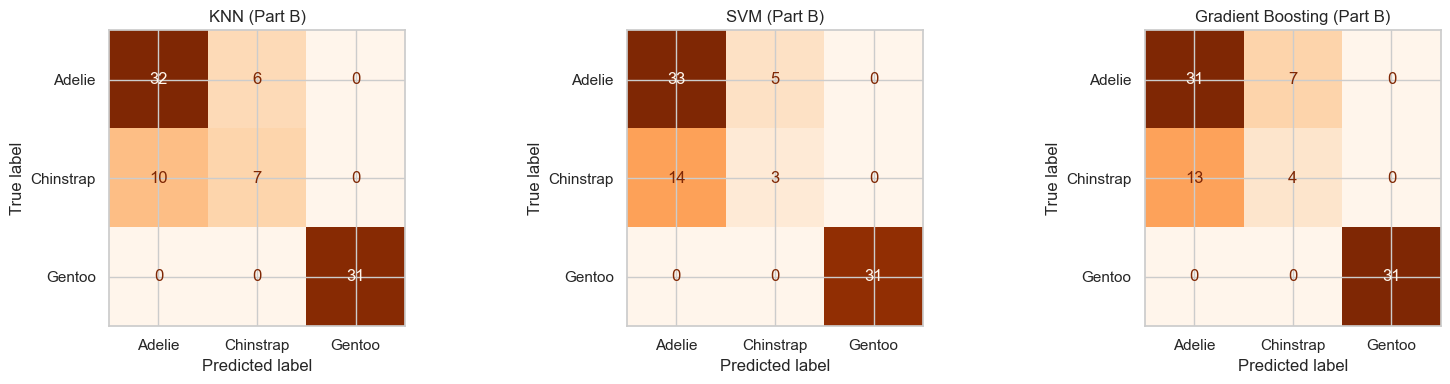

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, m) in zip(axes, models_B.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, cmap='Oranges', colorbar=False)
    ax.set_title(f'{name} (Part B)')
plt.tight_layout(); plt.show()

In [28]:
from sklearn.metrics import recall_score

classes = ['Adelie', 'Chinstrap', 'Gentoo']
pd.DataFrame({name: recall_score(y_test, m.predict(X_test), labels=classes, average=None)
              for name, m in models_B.items()}, index=classes).round(3).rename_axis('Recall ของแต่ละสายพันธุ์')

,KNN,SVM,Gradient Boosting
Recall ของแต่ละสายพันธุ์,,,
Adelie,0.842,0.868,0.816
Chinstrap,0.412,0.176,0.235
Gentoo,1.000,1.000,1.000


### 11.3 Classification Report ของโมเดลที่ดีที่สุด (Macro vs Weighted)

In [29]:
best_name_B = results_B['CV Macro F1'].idxmax()
best_B = models_B[best_name_B]
print("โมเดลที่ CV ดีที่สุด:", best_name_B, "\n")
print(classification_report(y_test, best_B.predict(X_test), digits=3))

โมเดลที่ CV ดีที่สุด: Gradient Boosting 

              precision    recall  f1-score   support

      Adelie      0.705     0.816     0.756        38
   Chinstrap      0.364     0.235     0.286        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          0.767        86
   macro avg      0.689     0.684     0.681        86
weighted avg      0.744     0.767     0.751        86



### 11.4 Learning Curve: ผลของการเพิ่มปริมาณข้อมูล
- ถ้าเส้น Train กับ CV **ยังห่างกันมาก** และ CV ยังขึ้นอยู่ → เพิ่มข้อมูลน่าจะช่วย
- ถ้าเส้น **ชนกันแล้วแบนราบ** → เพิ่มข้อมูลไม่ช่วย ต้องหา Feature ใหม่หรือเปลี่ยนโมเดล

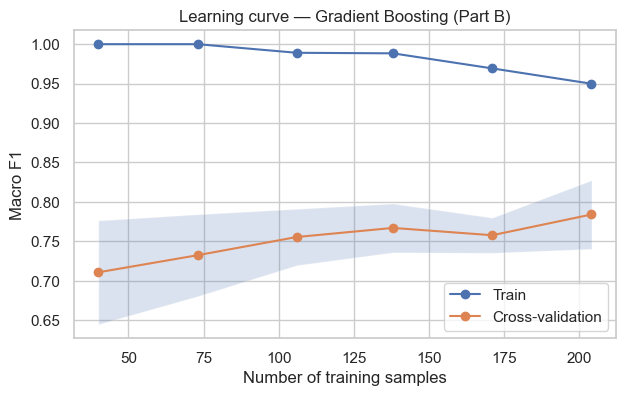

In [30]:
from sklearn.model_selection import learning_curve

sizes, tr_sc, cv_sc = learning_curve(best_B, X_train, y_train, cv=skf, scoring='f1_macro',
                                     train_sizes=np.linspace(0.2, 1.0, 6))
plt.figure(figsize=(7, 4))
plt.plot(sizes, tr_sc.mean(axis=1), 'o-', label='Train')
plt.plot(sizes, cv_sc.mean(axis=1), 'o-', label='Cross-validation')
plt.fill_between(sizes, cv_sc.mean(axis=1) - cv_sc.std(axis=1), cv_sc.mean(axis=1) + cv_sc.std(axis=1), alpha=0.2)
plt.xlabel('Number of training samples'); plt.ylabel('Macro F1'); plt.title(f'Learning curve — {best_name_B} (Part B)')
plt.legend(); plt.show()

### 11.5 การวิเคราะห์ผล Part B

| โมเดล | CV Macro F1 | Train Acc | Test Acc | Macro F1 | Weighted F1 | Recall Chinstrap |
|---|---|---|---|---|---|---|
| KNN | 0.788 | 0.852 | **0.814** | **0.756** | **0.806** | **0.41** (7/17) |
| SVM | 0.778 | 0.852 | 0.779 | 0.672 | 0.751 | 0.18 (3/17) |
| Gradient Boosting | **0.789** | 0.945 | 0.767 | 0.681 | 0.751 | 0.24 (4/17) |

**อ่าน Confusion Matrix 3×3**
- **Gentoo ถูกหมดทุกโมเดล (31/31)** — ตัวใหญ่ ครีบยาว แยกออกง่ายแม้ไม่มีความยาวปาก
- **ความผิดพลาดเกือบทั้งหมดคือ Adelie ↔ Chinstrap** — ขนาดตัวใกล้กันมาก (ข้อ 5.3) โดยเฉพาะ **Chinstrap ถูกทำนายเป็น Adelie** 10–14 จาก 17 ตัว

**Macro vs Weighted F1**
- Weighted F1 (0.75–0.81) **สูงกว่า** Macro F1 (0.67–0.76) เพราะคลาสที่ทำนายได้ต่ำที่สุด (Chinstrap) มีจำนวนน้อยที่สุด → ถูกถ่วงน้ำหนักน้อย
- ถ้ารายงานเพียง Accuracy (~0.78–0.81) หรือ Weighted F1 จะ **มองไม่เห็นว่า Chinstrap แทบทำนายไม่ได้** → ใช้ **Macro F1 + Recall รายคลาส**

**การเลือกโมเดล**
- CV เลือก Gradient Boosting (0.789) แต่ KNN (0.788) **ต่างกันเพียง 0.001 = ถือว่าเสมอกัน**
- Gradient Boosting **Overfit** (Train 0.945 vs Test 0.767) ขณะที่ KNN ช่องว่างน้อยกว่า (0.852 vs 0.814) และทำนาย Chinstrap ได้ดีที่สุด
- → เมื่อคะแนน CV เสมอกัน ให้เลือกตัวที่ **Overfit น้อยกว่า / เรียบง่ายกว่า** = **KNN**

**Learning curve (Gradient Boosting)**
- CV เพิ่มจาก ~0.71 → ~0.78 เมื่อข้อมูลเพิ่ม และยังห่างจาก Train (~0.95) มาก → **เพิ่มข้อมูลน่าจะช่วยได้อีก**

> **บทเรียนสำคัญ:** เพิ่ม `island` กลับเข้าไป (แบบฝึกหัดข้อ 1) Test Acc ขึ้นเป็น **0.907** และ Macro F1 **0.882**
> → **การเลือก Feature ที่ดีสำคัญกว่าการเลือกโมเดล** (เปลี่ยนโมเดลได้ต่างกันเพียง ~5 จุด แต่เพิ่ม Feature เดียวได้เพิ่ม ~10 จุดขึ้นไป)

---
# ขั้นที่ 12: ใช้งานโมเดล — ทำนายเพนกวินตัวใหม่ และบันทึกโมเดล
Pipeline รับ **ข้อมูลดิบ** ได้โดยตรง (แม้มีค่าหาย) ไม่ต้องเตรียมข้อมูลเอง

In [31]:
new_penguins = pd.DataFrame({
    'island':            ['Biscoe', 'Dream', 'Torgersen'],
    'culmen_length_mm':  [47.5, 49.0, 38.5],
    'culmen_depth_mm':   [14.5, 18.5, 18.0],
    'flipper_length_mm': [215, 195, 190],
    'body_mass_g':       [5000, 3700, 3600],
    'sex':               ['MALE', np.nan, 'FEMALE'],
})
new_penguins['Predicted (SVM)'] = best_svm.predict(new_penguins)
new_penguins

,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,Predicted (SVM)
0,Biscoe,47.5,14.5,215,5000,MALE,Gentoo
1,Dream,49.0,18.5,195,3700,NaN,Chinstrap
2,Torgersen,38.5,18.0,190,3600,FEMALE,Adelie


In [32]:
import joblib

joblib.dump(best_svm, 'penguin_svm.joblib')          # บันทึกทั้ง Pipeline (รวม Preprocess)
loaded = joblib.load('penguin_svm.joblib')           # โหลดกลับมาใช้
print("โหลดแล้วทำนายได้:", loaded.predict(new_penguins.drop(columns='Predicted (SVM)')))
os.remove('penguin_svm.joblib')                      # ลบไฟล์ตัวอย่างทิ้ง

โหลดแล้วทำนายได้: ['Gentoo' 'Chinstrap' 'Adelie']


---
## รายการตรวจสอบ (Checklist): Multiclass Classification
- [ ] ตรวจค่าแปลกปลอม (เช่น `'.'`) ไม่ใช่เพียง `NaN`
- [ ] `stratify=y` ตอนแบ่งข้อมูล
- [ ] ใช้ **Pipeline + ColumnTransformer** → CV ไม่ Leak และทำนายข้อมูลดิบได้
- [ ] KNN / SVM ต้อง Scale, Tree ไม่ต้อง
- [ ] Tuning: GridSearchCV (ค่าน้อย) / RandomizedSearchCV (ค่าจำนวนมาก) ชื่อพารามิเตอร์ `model__xxx`
- [ ] รายงาน **Macro F1** + Confusion Matrix 3×3 + Classification Report
- [ ] ถ้าคะแนน 100% ให้ถามว่า "โจทย์ง่ายจริง หรือมี Leakage?"

## แบบฝึกหัด
1. ใน Part B ทดลองเพิ่ม `island` กลับเข้าไป (`make_preprocessor(num_B, ['island'])`) — คะแนนดีขึ้นเท่าใด
2. ทดลองเปลี่ยนโมเดลเป็น `RandomForestClassifier` และ `LogisticRegression` ใน Pipeline เดียวกัน

In [33]:
# เฉลยข้อ 1
pipe_B_island = Pipeline([('prep', make_preprocessor(num_B, ['island'])), ('model', SVC(random_state=42))])
pipe_B_island.set_params(**{k: v for k, v in searches_B['SVM'].best_params_.items()})
pipe_B_island.fit(X_train, y_train)
print(f"Part B + island  → Test Acc = {pipe_B_island.score(X_test, y_test):.3f}, "
      f"Macro F1 = {f1_score(y_test, pipe_B_island.predict(X_test), average='macro'):.3f}")

Part B + island  → Test Acc = 0.907, Macro F1 = 0.882
